# Fine-Tune a Large Language Model

## Notebook introduction: Fine-tuning a small LLM (Gemma 3 270M) for chat

This Jupyter notebook is a **hands-on lab** that guides you through the complete workflow of **fine-tuning a small instruction/chat LLM** on a dialogue dataset. It is designed to run on a **single GPU (≈8GB VRAM or more)** and focuses on practical, reproducible steps:

**data loading → baseline inference → evaluation → supervised fine-tuning (SFT) → LoRA fine-tuning (PEFT) → final evaluation**

---

## What you will learn

- How to run **zero-shot inference** with a chat model using its **chat template**.
- How to evaluate generations with lightweight automatic metrics:
  - **Token-level F1** (after normalization and token overlap)
  - **BLEU** (via SacreBLEU)
- How to fine-tune a model in two ways:
  - **Full supervised fine-tuning (SFT)** using TRL’s `SFTTrainer`
  - **Parameter-efficient fine-tuning (LoRA)** using PEFT’s `LoraConfig`
- How to **save, reload, and evaluate** fine-tuned checkpoints.

---

## Requirements

- This notebook requires **at least 8GB of GPU VRAM**.
- Please run it on **JupyterHub for Conversational Agents and Dialogue Systems**:  
  https://hub.comp-teach.qmul.ac.uk/

In [ ]:
import sys
!{sys.executable} -m pip install numpy==1.26.4
!{sys.executable} -m pip install transformers==5.2.0
!{sys.executable} -m pip install datasets==4.5.0
!{sys.executable} -m pip install huggingface_hub==1.4.1
!{sys.executable} -m pip install trl==0.28.0
!{sys.executable} -m pip install peft==0.18.1
!{sys.executable} -m pip install bitsandbytes==0.49.2
!{sys.executable} -m pip install sacrebleu==2.6.0
!{sys.executable} -m pip install matplotlib
!{sys.executable} -m pip install tqdm
# install packages below if necessary
# !{sys.executable} -m pip install torch==2.9.1
# !{sys.executable} -m pip install torchaudio==2.9.1
# !{sys.executable} -m pip install torchvision==0.24.1

In [ ]:
import random
import numpy as np
import torch
import transformers
from tqdm import tqdm

def set_seed(seed=42):
    """Forces deterministic behavior across all libraries."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    # Force PyTorch to use deterministic algorithms
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # Set Hugging Face transformers seed
    transformers.set_seed(seed)

# Call this immediately at the start of your script
set_seed(42)

/opt/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Load the dataset

In this tutorial, we use the **SmolTalk** dataset from the Hugging Face Hub, specifically the `everyday-conversations` configuration. This dataset contains short, dialogue-style examples that work well for learning how to fine-tune an instruction or chat model.

What the code does:

- **Downloads the dataset** from Hugging Face using `load_dataset(...)`.
- **Creates a small evaluation split** by sampling **5% of the training set** (with a fixed `seed=42` so results are reproducible).
- **Builds a `DatasetDict`** with three splits:
  - `train`: the remaining 95% of the original training data
  - `eval`: the 5% held-out portion used for validation during training
  - `test`: the dataset’s original test split (kept unchanged for final evaluation)

This setup is common in fine-tuning workflows: you train on `train`, monitor performance on `eval`, and report final results on `test`.

In [ ]:
# Load dataset
from datasets import load_dataset, DatasetDict
dataset = load_dataset("HuggingFaceTB/smoltalk", "everyday-conversations")
split = dataset["train"].train_test_split(test_size=0.05, seed=42)  # 5% eval
# Print formatted test prompt to verify
dataset = DatasetDict({
    "train": split["train"],
    "eval": split["test"],   # rename held-out part to eval
    "test": dataset["test"],      # keep original test
})

# Load the model

Before downloading the model, you need access through Hugging Face.

1. Log in to Hugging Face and request access to **google/gemma-3-270m-it**:  
   https://huggingface.co/google/gemma-3-270m-it

2. Create a Hugging Face access token with **at least “read” permission**:  
   https://huggingface.co/docs/hub/en/security-tokens

3. Paste your token into the next code cell (where indicated) so the script can download the model.

In [ ]:
from huggingface_hub import login
# your code goes here
login()  # paste your own token when prompted; never hard-code it

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from trl import SFTConfig, SFTTrainer

# Set device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Configure model and tokenizer
model_name = "google/gemma-3-270m-it"

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="eager"
)
tokenizer = AutoTokenizer.from_pretrained(model_name)

Next we test the **base model** by generating an answer for a randomly selected example from the test split. It formats the user message using Gemma’s **chat template** and then runs text generation with a maximum of 256 new tokens. Finally, it prints the question, the reference answer from the dataset, and the model’s generated answer for comparison.

In [ ]:
from transformers import pipeline

from random import randint
import re

# Load the model and tokenizer into the pipeline
pipe = pipeline("text-generation", model=model, tokenizer=tokenizer)

# Load a random sample from the test dataset
rand_idx = randint(0, len(dataset["test"])-1)
test_sample = dataset["test"][rand_idx]

# Convert as test example into a prompt with the Gemma template
prompt = pipe.tokenizer.apply_chat_template(test_sample["messages"][:1], tokenize=False, add_generation_prompt=True)
outputs = pipe(prompt, max_new_tokens=256, disable_compile=True)

# Extract the user query and original answer
print(f"Question:\n{test_sample['messages'][0]['content']}\n")
print(f"Original Answer:\n{test_sample['messages'][1]['content']}\n")
print(f"Generated Answer (base model):\n{outputs[0]['generated_text'][len(prompt):].strip()}")

Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'disable_compile'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question:
Hi
Original Answer:
Hello! How can I help you today?
Generated Answer (base model):
Hi there! How can I help you today?


In [ ]:
print(tokenizer.chat_template)

{{ bos_token }}
{%- if messages[0]['role'] == 'system' -%}
    {%- if messages[0]['content'] is string -%}
        {%- set first_user_prefix = messages[0]['content'] + '
' -%}
    {%- else -%}
        {%- set first_user_prefix = messages[0]['content'][0]['text'] + '
' -%}
    {%- endif -%}
    {%- set loop_messages = messages[1:] -%}
{%- else -%}
    {%- set first_user_prefix = "" -%}
    {%- set loop_messages = messages -%}
{%- endif -%}
{%- for message in loop_messages -%}
    {%- if (message['role'] == 'user') != (loop.index0 % 2 == 0) -%}
        {{ raise_exception("Conversation roles must alternate user/assistant/user/assistant/...") }}
    {%- endif -%}
    {%- if (message['role'] == 'assistant') -%}
        {%- set role = "model" -%}
    {%- else -%}
        {%- set role = message['role'] -%}
    {%- endif -%}
    {{ '<start_of_turn>' + role + '
' + (first_user_prefix if loop.first else "") }}
    {%- if message['content'] is string -%}
        {{ message['content'] | trim }}
  

# Evaluation
### Evaluation: what this code measures

This evaluation script compares the model’s generated answers (**predictions**) against the dataset’s reference answers (**ground truths**) using two common text metrics:

- **Token-level F1 (overlap-based accuracy)**  
  We first *normalize* both texts (lowercase, remove punctuation and articles like “a/an/the”, and fix whitespace), then compute **precision**, **recall**, and **F1** based on how many tokens overlap.  
  - High F1 means the model used many of the same key words as the reference.  
  - It’s useful for checking whether the model captures the *main content*, but it does **not** fully measure fluency or correctness in open-ended dialogue.

- **BLEU (n-gram similarity via SacreBLEU)**  
  BLEU measures how similar the prediction is to the reference by matching short word sequences (n-grams).  
  - Higher BLEU usually means closer phrasing to the reference.  
  - Like F1, it works best when there is a relatively “expected” answer; it can underestimate good answers that are correct but phrased differently.

### Extra debugging outputs

Besides computing the average scores, the function also:
- Sorts all examples by F1 score
- Prints the **top 3 best** and **top 3 worst** examples  
This helps you quickly inspect where the model performs well and where it fails (e.g., missing key info, off-topic replies, or overly generic responses).

### What model performance you can test with this

With these metrics, you can mainly evaluate:
- **Content overlap / keyword coverage** (F1)
- **Similarity of wording to the reference** (BLEU)
- **Consistency across examples** by inspecting best/worst cases

These scores are helpful for tracking improvement during fine-tuning, but they don’t fully capture qualities like helpfulness, reasoning, safety, or conversational naturalness.

In [ ]:
import string
import re
from typing import List, Tuple, Dict, Optional
from collections import Counter
import sacrebleu
def normalize_answer(s: str) -> str:
    """Normalize text for evaluation."""

    def remove_articles(text):
        return re.sub(r"\b(a|an|the)\b", " ", text)

    def white_space_fix(text):
        return " ".join(text.split())

    def remove_punc(text):
        return "".join(ch for ch in text if ch not in set(string.punctuation))

    def lower(text):
        return text.lower()

    return white_space_fix(remove_articles(remove_punc(lower(s))))

def compute_f1(prediction: str, ground_truth: str) -> float:
    """Compute token-level F1 score."""
    pred_tokens = normalize_answer(prediction).split()
    gold_tokens = normalize_answer(ground_truth).split()

    if len(pred_tokens) == 0 and len(gold_tokens) == 0:
        return 1.0
    if len(pred_tokens) == 0 or len(gold_tokens) == 0:
        return 0.0

    pred_counter = Counter(pred_tokens)
    gold_counter = Counter(gold_tokens)
    common_tokens = pred_counter & gold_counter
    num_same = sum(common_tokens.values())

    if num_same == 0:
        return 0.0

    precision = num_same / len(pred_tokens)
    recall = num_same / len(gold_tokens)
    return (2 * precision * recall) / (precision + recall)

def evaluate_predictions(predictions: List[str], ground_truths: List[str]) -> Dict[str, float]:
    """Compute average F1 and BLEU scores."""
    assert len(predictions) == len(ground_truths)

    # F1 scores
    f1_scores = [compute_f1(pred, gold) for pred, gold in zip(predictions, ground_truths)]
    avg_f1 = sum(f1_scores) / len(f1_scores) * 100

    # BLEU score
    bleu = sacrebleu.corpus_bleu(predictions, [ground_truths])

    scored_examples = list(zip(predictions, ground_truths, f1_scores))
    scored_examples.sort(key=lambda x: x[2], reverse=True)
    
    print("\n=== Top 3 Best Examples (Highest F1) ===")
    for i, (pred, gold, score) in enumerate(scored_examples[:3]):
        print(f"\n[{i+1}] F1: {score:.4f}")
        print(f"Predicted: {pred}")
        print(f"Reference: {gold}")
    
    print("\n=== Top 3 Worst Examples (Lowest F1) ===")
    for i, (pred, gold, score) in enumerate(scored_examples[-3:]):
        print(f"\n[{i+1}] F1: {score:.4f}")
        print(f"Predicted: {pred}")
        print(f"Reference: {gold}")
    
    return {
        "average_f1": avg_f1,
        "bleu": float(bleu.score),
        "total": len(predictions),
        "f1_scores": f1_scores
    }

In [ ]:
def evaluation(model, tokenizer, dataset,print_sample = 5):
    printed_sample = 0
    predictions = []
    ground_truths = []
    for sample in tqdm(dataset["test"]):
        prompt_messages = sample["messages"][0:-1]
        ground_truth = sample["messages"][-1]["content"]
        
        # Format the prompt using the model's chat template
        input_ids = tokenizer.apply_chat_template(
            prompt_messages,
            add_generation_prompt=True, # This adds the special token prompting the assistant to speak
            return_tensors="pt"
        ).to(model.device)
        input_ids

        # Generate the response
        with torch.no_grad():
            outputs = model.generate(
                **input_ids,
                max_new_tokens=100,       # Adjust based on how long you expect the answer to be
                temperature=0.3,          # Lower temperature for more factual, focused answers
                do_sample=True,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.convert_tokens_to_ids("<end_of_turn>")
            )
        
        # Decode and print the results
        prompt_length = input_ids["input_ids"].shape[-1]
        
        # Use that length to slice the generated tokens
        generated_tokens = outputs[0][prompt_length:]
        generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True)

        predictions.append(generated_text)
        ground_truths.append(ground_truth)
        
        # option: print
        if print_sample - 1 >= printed_sample:
            print("--- User Prompt ---")
            print(prompt_messages[-1]["content"])
            print("\n--- Ground Truth (Expected) ---")
            print(ground_truth)
            print("\n--- Model Generation ---")
            print(generated_text)
            printed_sample+=1
    return evaluate_predictions(predictions, ground_truths)

# Zero-Shot Evaluation
Prior to fine-tuning Gemma3, we conduct zero-shot testing on the base model.

In [ ]:
results = evaluation(model, tokenizer, dataset)
print("="*60)
print("Baseline F1:", results["average_f1"])
print("Baseline BLEU:", results["bleu"])

--- User Prompt ---
Awesome, thank you for the recommendations!
--- Ground Truth (Expected) ---
You're welcome! Have a great time in Paris!
--- Model Generation ---
You're welcome! I'm glad I could help. I'll be sure to check them out.


--- User Prompt ---
What type of cameras does Sony make?
--- Ground Truth (Expected) ---
Sony makes a variety of cameras, including mirrorless cameras, point-and-shoot cameras, and action cameras like the Sony RX series and the Sony Alpha series.
--- Model Generation ---
Sony is known for its high-end and versatile cameras, including:
*   **Sony Alpha series:** These are known for their excellent image quality, advanced features, and versatility.
*   **Sony Alpha series:** These are popular for their stunning images and features, including the "Sony Alpha" name.
*   **Sony Alpha series:** These are known for their high-end and sophisticated designs.
*   **Sony Alpha series:** These are popular for their versatility and ability to


--- User Prompt ---
Can you give me an example of a shape that is not symmetrical?
--- Ground Truth (Expected) ---
A triangle with different side lengths is not symmetrical because it doesn't have equal sides or angles, and it doesn't look the same when you flip it over.
--- Model Generation ---
Yes, a circle is not symmetrical.


--- User Prompt ---
That sounds amazing. What's the best time to visit Bora Bora?
--- Ground Truth (Expected) ---
The best time to visit Bora Bora is during the dry season, from May to October, when the weather is calm and sunny.
--- Model Generation ---
The best time to visit Bora Bora is during the **dry season (June to November)**. This is the dry season, meaning the weather is generally pleasant and the crowds are smaller. However, it's still important to plan your trip accordingly.


--- User Prompt ---
That's interesting. I'll look into it.
--- Ground Truth (Expected) ---
You're welcome! I'm glad I could help you learn something new about the internet's history.
--- Model Generation ---
That's a great question! It's a very common and important topic.


=== Top 3 Best Examples (Highest F1) ===
[1] F1: 0.6341
Predicted: No, not all metals are magnetic. Some metals are not magnetic, and some are not ferromagnetic.
Reference: No, not all metals are magnetic. While some metals like iron, nickel, and cobalt are naturally magnetic, others like copper, aluminum, and silver are not.
[2] F1: 0.5517
Predicted: A smooth surface that reflects light well is a **mirror**.
Reference: A mirror is a good example of a smooth surface that reflects light well, which is why we can see ourselves clearly in it.
[3] F1: 0.5091
Predicted: The best time to visit Bora Bora is during the **dry season (June to November)**. This is the dry season, meaning the weather is generally pleasant and the crowds are smaller. However, it's still important to plan your trip accordingly.
Reference: The best time to visit Bora Bora is during the dry season, from May to October, when the weather is calm and sunny.
=== Top 3 Worst Examples (Lowest F1) ===
[1] F1: 0.0000
Predicte

# Supervised Fine-Tuning (SFT) setup

This code configures and launches **supervised fine-tuning** using TRL’s `SFTTrainer`, which trains the model to imitate the dataset’s target responses (i.e., learn to produce the “assistant” answer given the “user” prompt). The `SFTConfig` object defines the training recipe (how data is fed, how optimization runs, how often we evaluate/log, and what precision to use), and then `SFTTrainer` ties together the **model**, **tokenizer**, and the **train/eval splits**.

## Huggingface Documentation
https://huggingface.co/docs/trl/v0.28.0/en/sft_trainer#trl.SFTConfig

https://huggingface.co/docs/trl/v0.28.0/en/sft_trainer#trl.SFTTrainer


Key parameters to understand:

- **Sequence handling**
  - `max_length`: the maximum token length of each training sequence (longer inputs get truncated).
  - `packing`: whether multiple short samples are concatenated into one long sequence to improve GPU utilization.

- **Training loop**
  - `num_train_epochs`: how many passes over the training set.
  - `per_device_train_batch_size`: how many examples are processed per GPU step.
  - `gradient_accumulation_steps`: simulates a larger batch by accumulating gradients across multiple steps before updating weights.

- **Memory and speed**
  - `gradient_checkpointing`: trades extra compute for lower memory usage.
  - `optim`: selects the optimizer implementation (some options are faster on modern GPUs).
  - `fp16` / `bf16`: enables mixed-precision training depending on the model’s dtype for faster training and reduced memory.

- **Learning dynamics**
  - `learning_rate`: controls the size of weight updates.
  - `lr_scheduler_type`: controls how the learning rate changes over time.

- **Evaluation, logging, and saving**
  - `eval_strategy` / `eval_steps`: decides when to run evaluation on the validation set.
  - `logging_steps`: how often to print / log training metrics.
  - `report_to`: where logs are sent (e.g., TensorBoard).
  - `save_strategy`: when checkpoints are saved.

- **Dataset formatting**
  - `dataset_kwargs` (e.g., `add_special_tokens`): ensures the dataset text is already formatted correctly (especially important when you apply a chat template yourself).

Finally, `SFTTrainer(...)` creates the training object by plugging in the model, config, tokenizer (as `processing_class`), and the `train` / `eval` datasets—ready for `trainer.train()`.

## Parameters that most affect GPU VRAM

- **`max_length`**: bigger sequences increase activation memory (often the *largest* VRAM driver).
- **`per_device_train_batch_size`**: larger batches scale activation memory roughly linearly.
- **`packing`**: when enabled, effective token count per step often increases (can raise VRAM if it leads to fuller sequences).
- **Precision (`fp16` / `bf16`)**: lower precision reduces memory for weights/activations compared to full precision.
- **`gradient_checkpointing`**: reduces activation memory (saves VRAM) at the cost of extra compute.
- **Optimizer choice (`optim`)**: different implementations and optimizer state handling can change VRAM usage.
- **Model/Tokenizer processing details (`processing_class`, dataset formatting)**: indirectly affects VRAM by changing actual tokenized length (more tokens → more VRAM).

Note: **`gradient_accumulation_steps`** usually increases *training time* rather than peak VRAM, because it simulates a larger batch without storing all activations at once (though it can slightly affect memory depending on implementation).

## Check Machine GPU(s) VRAM on JupyterHub or Your Own Machine with Nvidia GPU(s)

In [ ]:
!nvidia-smi

Wed Mar 18 06:20:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          On  |   00000000:C2:00.0 Off |                    0 |
| N/A   59C    P0            112W /  300W |     985MiB /   8192MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
from trl import SFTConfig, SFTTrainer

torch_dtype = model.dtype

args = SFTConfig(
    output_dir="sft_output",
    max_length=256,
    packing=False,
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="epoch",
    gradient_checkpointing=True,
    bf16=torch.cuda.is_available(),
    report_to="none",
    dataset_kwargs={"add_special_tokens": False},
)

trainer = SFTTrainer(
    model=model,
    args=args,
    processing_class=tokenizer,
    train_dataset=dataset["train"],
    eval_dataset=dataset["eval"],
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


## Start Training

In [ ]:
trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': 2, 'pad_token_id': 0}.


Step,Training Loss,Validation Loss
50,1.150151,1.142845
100,1.155162,1.117703


TrainOutput(global_step=135, training_loss=1.2604344262017144, metrics={'train_runtime': 122.3916, 'train_samples_per_second': 17.542, 'train_steps_per_second': 1.103, 'total_flos': 293366313166080.0, 'train_loss': 1.2604344262017144})

In [ ]:
save_dir = 'sft_output/'
trainer.save_model(save_dir)

## Plot Training Log

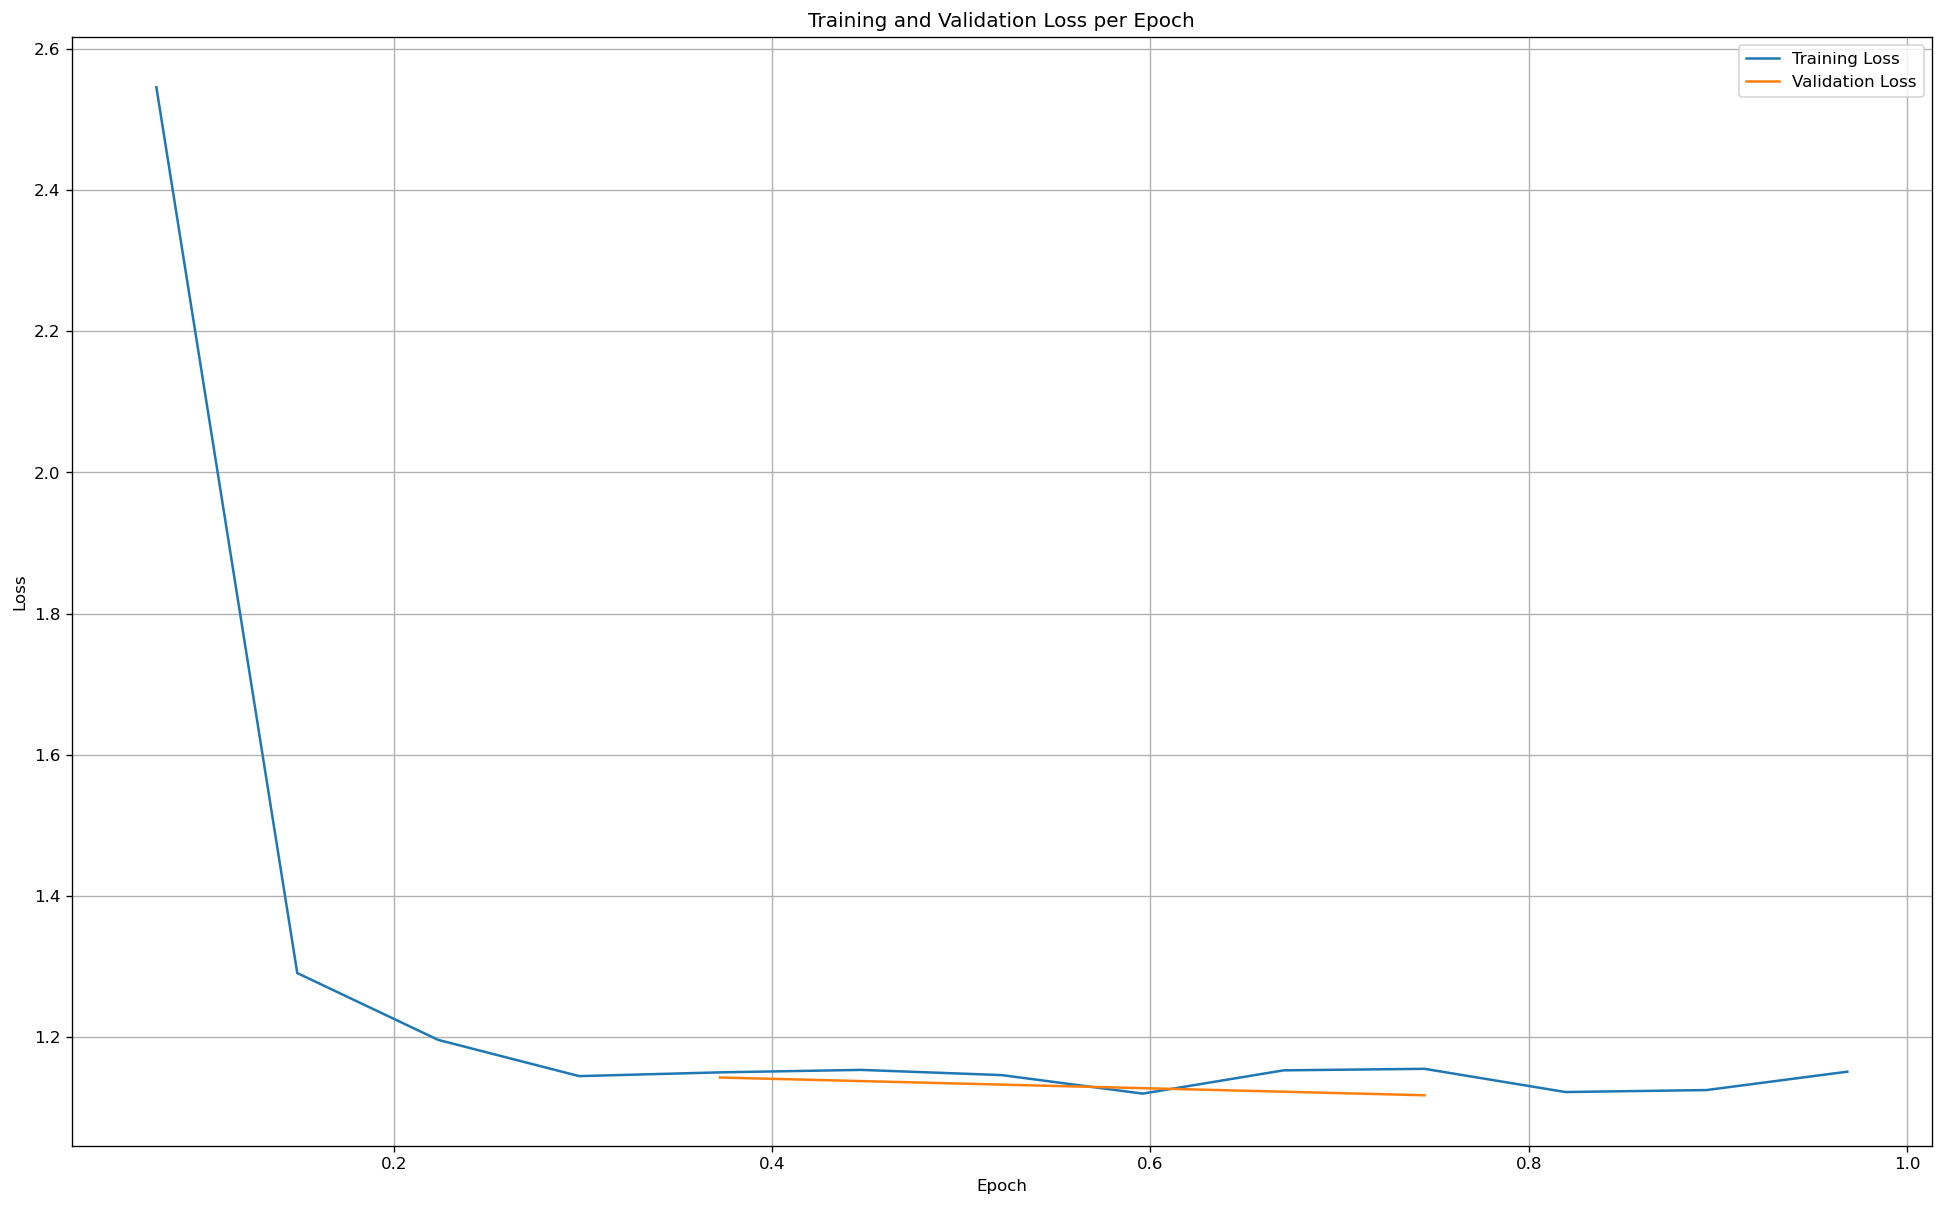

In [ ]:
import matplotlib.pyplot as plt

# Access the log history
log_history = trainer.state.log_history

# Extract training / validation loss
train_losses = [log["loss"] for log in log_history if "loss" in log]
epoch_train = [log["epoch"] for log in log_history if "loss" in log]
eval_losses = [log["eval_loss"] for log in log_history if "eval_loss" in log]
epoch_eval = [log["epoch"] for log in log_history if "eval_loss" in log]

# Plot the training loss
plt.figure(figsize=(20, 12), dpi=120)   # width, height in inches
plt.plot(epoch_train, train_losses, label="Training Loss")
plt.plot(epoch_eval, eval_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()

## Load SFT model

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = save_dir

# Load Model
sft_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="eager"
)
sft_tokenizer = AutoTokenizer.from_pretrained(model_id)

In [ ]:
print(sft_model)

Gemma3ForCausalLM(
  (model): Gemma3TextModel(
    (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 640, padding_idx=0)
    (layers): ModuleList(
      (0-17): 18 x Gemma3DecoderLayer(
        (self_attn): Gemma3Attention(
          (q_proj): Linear(in_features=640, out_features=1024, bias=False)
          (k_proj): Linear(in_features=640, out_features=256, bias=False)
          (v_proj): Linear(in_features=640, out_features=256, bias=False)
          (o_proj): Linear(in_features=1024, out_features=640, bias=False)
          (q_norm): Gemma3RMSNorm((256,), eps=1e-06)
          (k_norm): Gemma3RMSNorm((256,), eps=1e-06)
        )
        (mlp): Gemma3MLP(
          (gate_proj): Linear(in_features=640, out_features=2048, bias=False)
          (up_proj): Linear(in_features=640, out_features=2048, bias=False)
          (down_proj): Linear(in_features=2048, out_features=640, bias=False)
          (act_fn): GELUTanh()
        )
        (input_layernorm): Gemma3RMSNorm((640,), eps=1e-06)

## Evaluate SFT Model

In [ ]:
results = evaluation(sft_model, sft_tokenizer, dataset)
print("="*60)
print("Baseline F1:", results["average_f1"])
print("Baseline BLEU:", results["bleu"])

--- User Prompt ---
Awesome, thank you for the recommendations!
--- Ground Truth (Expected) ---
You're welcome! Have a great time in Paris!
--- Model Generation ---
You're welcome! Enjoy your trip to Paris.


--- User Prompt ---
What type of cameras does Sony make?
--- Ground Truth (Expected) ---
Sony makes a variety of cameras, including mirrorless cameras, point-and-shoot cameras, and action cameras like the Sony RX series and the Sony Alpha series.
--- Model Generation ---
Sony's cameras are known for their high-quality image quality, excellent video capabilities, and a focus on ergonomics. They're often used in professional photography and videography.


--- User Prompt ---
Can you give me an example of a shape that is not symmetrical?
--- Ground Truth (Expected) ---
A triangle with different side lengths is not symmetrical because it doesn't have equal sides or angles, and it doesn't look the same when you flip it over.
--- Model Generation ---
A rectangle is not symmetrical because it has two equal sides and two right angles, and it looks the same when you flip it over or rotate it.


--- User Prompt ---
That sounds amazing. What's the best time to visit Bora Bora?
--- Ground Truth (Expected) ---
The best time to visit Bora Bora is during the dry season, from May to October, when the weather is calm and sunny.
--- Model Generation ---
The best time to visit Bora Bora is during the dry season, which typically occurs from late June to mid-October. This offers pleasant weather and fewer crowds.


--- User Prompt ---
That's interesting. I'll look into it.
--- Ground Truth (Expected) ---
You're welcome! I'm glad I could help you learn something new about the internet's history.
--- Model Generation ---
You're welcome! I hope you find the information you need.


=== Top 3 Best Examples (Highest F1) ===
[1] F1: 1.0000
Predicted: You're welcome.
Reference: You're welcome.
[2] F1: 1.0000
Predicted: You're welcome! Have a great time at the mall.
Reference: You're welcome! Have a great time at the mall.
[3] F1: 0.7586
Predicted: You're welcome! I hope you have a great time with your family and enjoy the outdoor activities.
Reference: You're welcome! I hope you and your family have a great time at the soccer league.
=== Top 3 Worst Examples (Lowest F1) ===
[1] F1: 0.0000
Predicted: That's a good point. It's easy to misinterpret these cues, so it's best to be mindful of your own body language and try to be open and honest with your family members.
Reference: Okay, I think I understand now.
[2] F1: 0.0000
Predicted: I'd be happy to help you with that. What's your favorite healthy snack?
Reference: Okay, thanks for the suggestions.
[3] F1: 0.0000
Predicted: One more unusual instrument is the Vibraphone. It's a percussion instrument that produces a dist

## Free the Memory

In [ ]:
del sft_model, sft_tokenizer
del trainer
torch.cuda.empty_cache()

# LoRA Fine-Tuning (PEFT) Setup

This code switches from full fine-tuning to **LoRA (Low-Rank Adaptation)** using PEFT: instead of updating all model weights, it inserts small trainable adapter matrices into selected layers and trains only those adapters. You still use TRL’s `SFTTrainer` for the supervised fine-tuning loop, but you pass a `peft_config` so the trainer trains the LoRA adapters (and optionally a few extra modules) rather than the full model.

## Huggingface Documentation
https://huggingface.co/docs/peft/v0.18.0/en/package_reference/lora#peft.LoraConfig

https://huggingface.co/docs/trl/v0.28.0/en/sft_trainer#trl.SFTTrainer

Key parameters to understand:

- **LoRA adapter design**
  - `r`: the rank of the low-rank adapters (controls adapter capacity).
  - `lora_alpha`: scaling factor for the adapter updates (affects update magnitude).
  - `lora_dropout`: dropout applied within LoRA adapters (regularization).
  - `target_modules`: which layers receive LoRA adapters (e.g., linear layers).
  - `bias`: whether and how biases are trained.
  - `task_type`: tells PEFT the task format (here, causal language modeling).

- **What gets saved/trained beyond adapters**
  - `modules_to_save`: extra modules saved (and typically trained) alongside LoRA, useful when you need to keep changes in embeddings or the output head (e.g., when adding special tokens).

- **Training configuration (same idea as SFT)**
  - `max_length`, `packing`
  - `per_device_train_batch_size`, `gradient_accumulation_steps`, `num_train_epochs`
  - precision (`fp16` / `bf16`), optimizer, evaluation/logging settings, dataset formatting

## Parameters that most affect GPU VRAM

- **`max_length`** and **`per_device_train_batch_size`**: still the biggest drivers (more tokens / more examples → more activation memory).
- **Precision (`fp16` / `bf16`)**: lowers memory for activations and parameters.
- **`gradient_checkpointing`**: reduces activation memory if enabled.
- **LoRA-specific knobs**
  - **`r`**: higher rank increases the number of trainable adapter parameters and their optimizer states (more VRAM).
  - **`target_modules`**: adapting more layers (or bigger layers) increases trainable parameters and optimizer memory.
  - **`modules_to_save`**: saving/training extra modules like embeddings or the LM head adds trainable parameters and optimizer states (more VRAM).

Why LoRA is usually lighter than full fine-tuning: optimizer states and gradients are stored for **far fewer parameters**, so VRAM drops significantly compared to updating the entire model (even though activations still depend mainly on sequence length and batch size).

In [ ]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

torch_dtype = model.dtype

peft_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
)

# Configure trainer
args = SFTConfig(
    output_dir="lora_output",
    max_length=256,
    packing=False,
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_ratio=0.03,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="epoch",
    gradient_checkpointing=True,
    bf16=torch.cuda.is_available(),
    report_to="none",
    dataset_kwargs={"add_special_tokens": False},
)

# Create Trainer object
trainer = SFTTrainer(
    model=model,
    args=args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["eval"],
    processing_class=tokenizer,
    peft_config=peft_config,
)

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


## Start LoRA Training

In [ ]:
trainer.train()

Step,Training Loss,Validation Loss
50,1.058961,1.106604
100,1.122374,1.089539


TrainOutput(global_step=135, training_loss=1.0823385344611274, metrics={'train_runtime': 157.9633, 'train_samples_per_second': 13.592, 'train_steps_per_second': 0.855, 'total_flos': 295522215732480.0, 'train_loss': 1.0823385344611274})

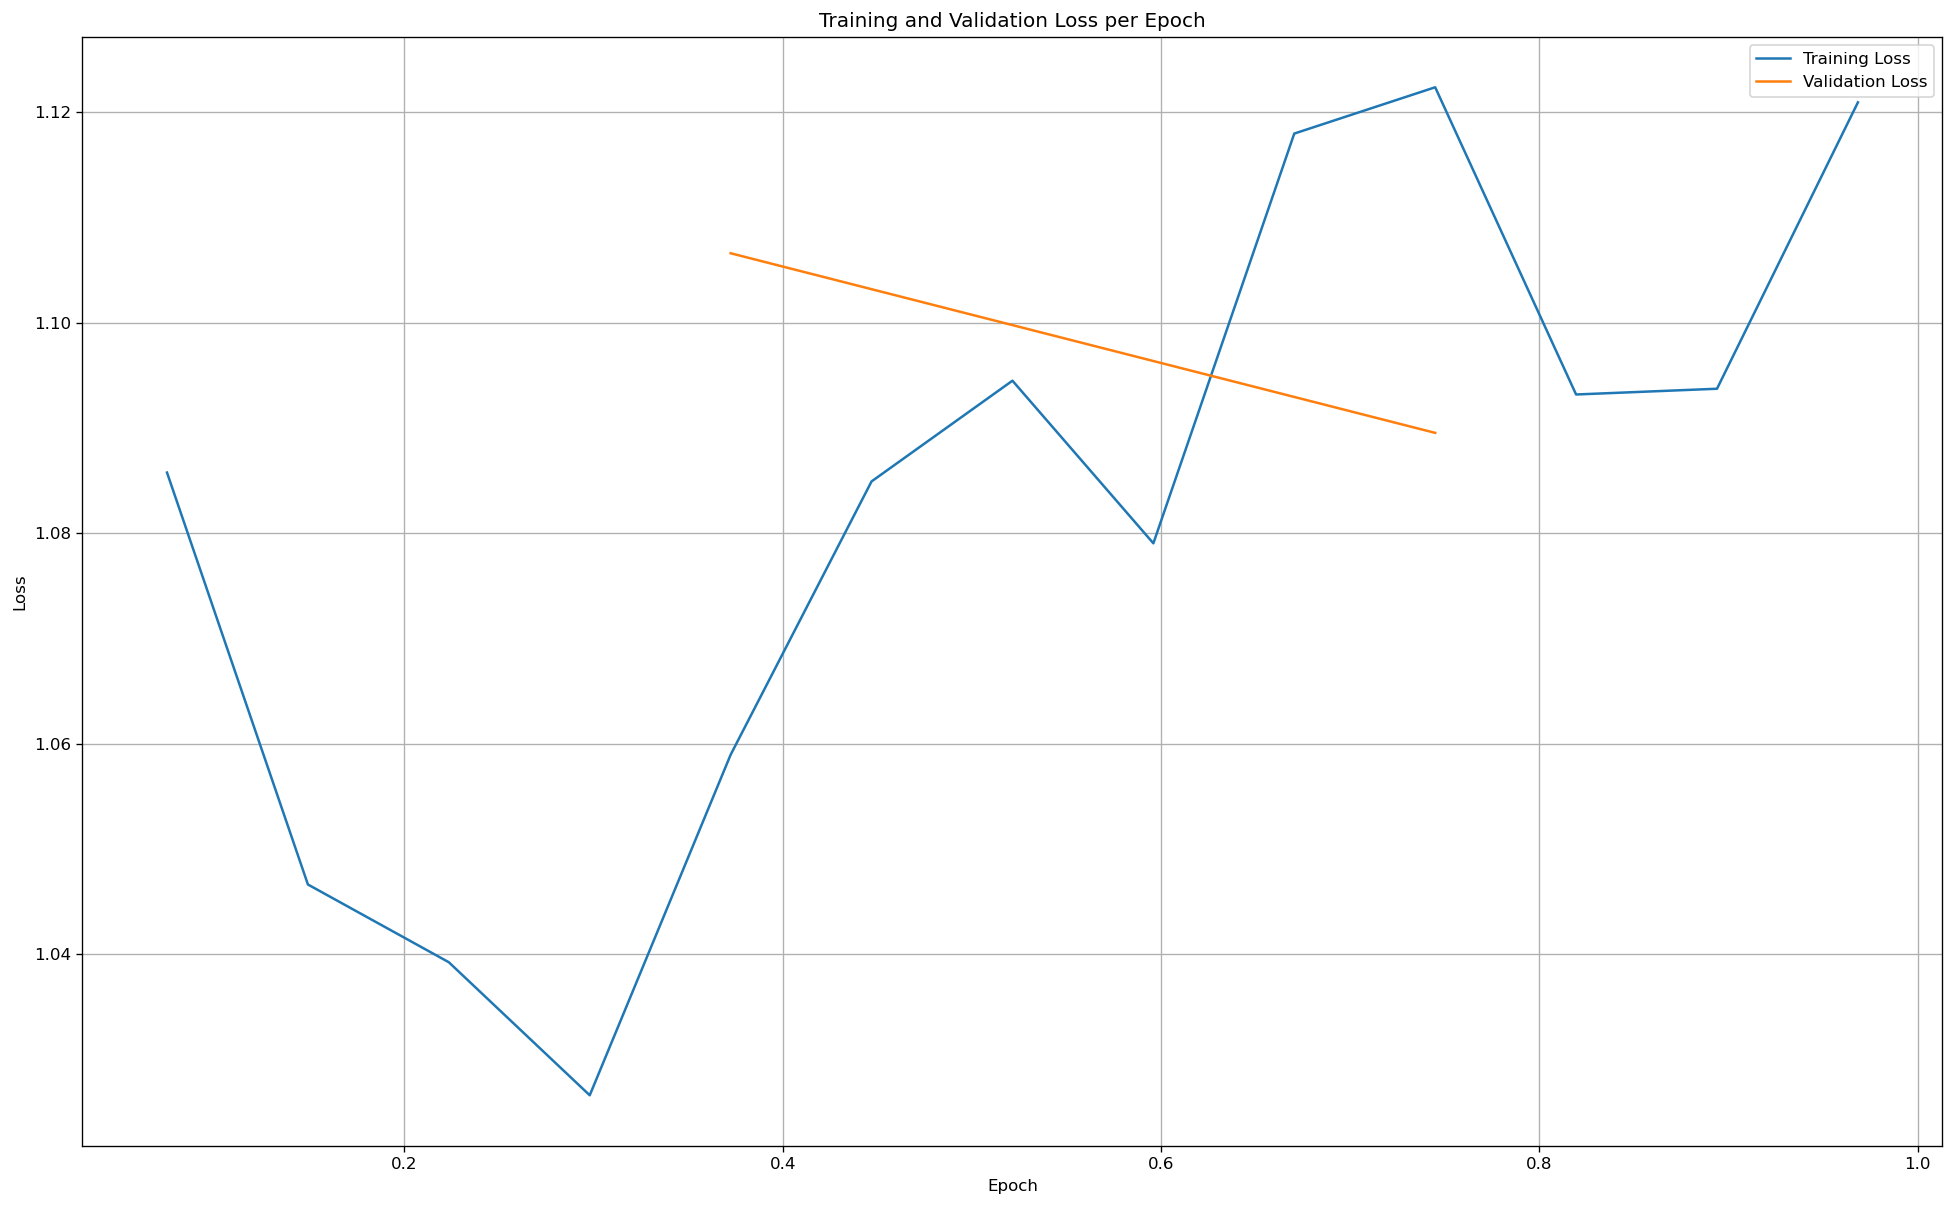

In [ ]:
import matplotlib.pyplot as plt
# Access the log history
log_history = trainer.state.log_history

# Extract training / validation loss
train_losses = [log["loss"] for log in log_history if "loss" in log]
epoch_train = [log["epoch"] for log in log_history if "loss" in log]
eval_losses = [log["eval_loss"] for log in log_history if "eval_loss" in log]
epoch_eval = [log["epoch"] for log in log_history if "eval_loss" in log]

# Plot the training loss
plt.figure(figsize=(20, 12), dpi=120)   # width, height in inches
plt.plot(epoch_train, train_losses, label="Training Loss")
plt.plot(epoch_eval, eval_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss per Epoch")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
save_dir = 'lora_output/'
trainer.save_model(save_dir)

In [ ]:
from peft import PeftModel

# Load Model base model
model = AutoModelForCausalLM.from_pretrained(model_name, low_cpu_mem_usage=True)

merged_save_dir = "merged_model/"
# Merge LoRA and base model and save
peft_model = PeftModel.from_pretrained(model, save_dir)
merged_model = peft_model.merge_and_unload()
merged_model.save_pretrained(merged_save_dir, safe_serialization=True, max_shard_size="2GB")

processor = AutoTokenizer.from_pretrained(save_dir)
processor.save_pretrained(merged_save_dir)

('merged_model/tokenizer_config.json',
 'merged_model/chat_template.jinja',
 'merged_model/tokenizer.json')

In [ ]:
print(peft_model)

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Gemma3ForCausalLM(
      (model): Gemma3TextModel(
        (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 640, padding_idx=0)
        (layers): ModuleList(
          (0-17): 18 x Gemma3DecoderLayer(
            (self_attn): Gemma3Attention(
              (q_proj): Linear(in_features=640, out_features=1024, bias=False)
              (k_proj): Linear(in_features=640, out_features=256, bias=False)
              (v_proj): Linear(in_features=640, out_features=256, bias=False)
              (o_proj): Linear(in_features=1024, out_features=640, bias=False)
              (q_norm): Gemma3RMSNorm((256,), eps=1e-06)
              (k_norm): Gemma3RMSNorm((256,), eps=1e-06)
            )
            (mlp): Gemma3MLP(
              (gate_proj): Linear(in_features=640, out_features=2048, bias=False)
              (up_proj): Linear(in_features=640, out_features=2048, bias=False)
              (down_proj): Linear(in_features=2048, out_

In [ ]:
# Load Model
model_id = merged_save_dir

merged_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="eager"
)
merged_tokenizer = AutoTokenizer.from_pretrained(model_id)

In [ ]:
print(merged_model)

Gemma3ForCausalLM(
  (model): Gemma3TextModel(
    (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 640, padding_idx=0)
    (layers): ModuleList(
      (0-17): 18 x Gemma3DecoderLayer(
        (self_attn): Gemma3Attention(
          (q_proj): Linear(in_features=640, out_features=1024, bias=False)
          (k_proj): Linear(in_features=640, out_features=256, bias=False)
          (v_proj): Linear(in_features=640, out_features=256, bias=False)
          (o_proj): Linear(in_features=1024, out_features=640, bias=False)
          (q_norm): Gemma3RMSNorm((256,), eps=1e-06)
          (k_norm): Gemma3RMSNorm((256,), eps=1e-06)
        )
        (mlp): Gemma3MLP(
          (gate_proj): Linear(in_features=640, out_features=2048, bias=False)
          (up_proj): Linear(in_features=640, out_features=2048, bias=False)
          (down_proj): Linear(in_features=2048, out_features=640, bias=False)
          (act_fn): GELUTanh()
        )
        (input_layernorm): Gemma3RMSNorm((640,), eps=1e-06)

## Evaluate LoRA Model

In [ ]:
results = evaluation(merged_model, merged_tokenizer, dataset)
print("="*60)
print("Baseline F1:", results["average_f1"])
print("Baseline BLEU:", results["bleu"])

--- User Prompt ---
Awesome, thank you for the recommendations!
--- Ground Truth (Expected) ---
You're welcome! Have a great time in Paris!
--- Model Generation ---
You're welcome! I'm glad I could help. I'm happy to share some more information about Paris.


--- User Prompt ---
What type of cameras does Sony make?
--- Ground Truth (Expected) ---
Sony makes a variety of cameras, including mirrorless cameras, point-and-shoot cameras, and action cameras like the Sony RX series and the Sony Alpha series.
--- Model Generation ---
Sony is known for its high-end, high-quality cameras. They offer a variety of models, including:
*   **Sony Alpha series:** These are known for their exceptional image quality, excellent zoom capabilities, and advanced features like advanced image stabilization.
*   **Sony Alpha series:** These are popular for their versatility and ability to handle a wide range of shooting situations.
*   **Sony Alpha series:** These are known for their elegant designs and focus on performance.


--- User Prompt ---
Can you give me an example of a shape that is not symmetrical?
--- Ground Truth (Expected) ---
A triangle with different side lengths is not symmetrical because it doesn't have equal sides or angles, and it doesn't look the same when you flip it over.
--- Model Generation ---
Yes, a rectangle is not symmetrical.


--- User Prompt ---
That sounds amazing. What's the best time to visit Bora Bora?
--- Ground Truth (Expected) ---
The best time to visit Bora Bora is during the dry season, from May to October, when the weather is calm and sunny.
--- Model Generation ---
The best time to visit Bora Bora is during the **dry season (June to November)**. This is the dry season, which means there are fewer crowds, lower prices, and fewer crowds on the islands. However, it's still a beautiful time to visit, with stunning scenery and vibrant colors.


--- User Prompt ---
That's interesting. I'll look into it.
--- Ground Truth (Expected) ---
You're welcome! I'm glad I could help you learn something new about the internet's history.
--- Model Generation ---
That's great to know! I'm glad to help. What would you like to know more about?


=== Top 3 Best Examples (Highest F1) ===
[1] F1: 0.7000
Predicted: No, not all metals are magnetic. Some metals, like gold and silver, are not magnetic.
Reference: No, not all metals are magnetic. While some metals like iron, nickel, and cobalt are naturally magnetic, others like copper, aluminum, and silver are not.
[2] F1: 0.5778
Predicted: Yes, Mapo tofu is generally quite easy to make at home. It's a simple dish with a few key ingredients. You can adjust the spices and seasonings to your liking.
Reference: Yes, Mapo tofu is relatively easy to make at home, and you can find many simple recipes online.
[3] F1: 0.5000
Predicted: A smooth surface that reflects light well is a **mirror** or a **mirror surface**.
Reference: A mirror is a good example of a smooth surface that reflects light well, which is why we can see ourselves clearly in it.
=== Top 3 Worst Examples (Lowest F1) ===
[1] F1: 0.0000
Predicted: That's a great clarification! Thanks for the information. I'm glad I could help